In questo codice testo l'algoritmo di Nikolson per una condizione al bordo di cui è nota la g(t) risultante

In [ ]:
import sys
sys.path.insert(0, "../")

import numpy as np
import matplotlib.pyplot as plt
from src.Heat1DCrankNicolson import Heat1DCrankNicolson

plt.style.use("../styles/plots.mplstyle")
np.random.seed(42)

In [7]:
L = 0.5
Tf = 2500
nt = 50000
D = 0.001
wanted_r = 0.5

solver = Heat1DCrankNicolson(L,Tf,nt,D,0,wanted_r=wanted_r)
solver.info()


-----------------------------Solver info------------------------------

Diffusion time:                                               2.50e+02
dx:                                                           1.00e-02
dt:                                                           5.00e-02
nt:                                                              50000
nx:                                                                 51
r:                                                            5.00e-01
h:                                                            0.00e+00


Slope (m): -5.0888935797392304e-11
Intercept (b): 0.9999999999972355
Expected Slope (m): 0.0
Slope (m): -0.6666666666668354
Intercept (b): 0.9999999999999739
Expected Slope (m): -0.6666666666666666
Slope (m): -1.428571428571477
Intercept (b): 0.9999999999999751
Expected Slope (m): -1.4285714285714286
Slope (m): -1.6666666666666883
Intercept (b): 0.9999999999999799
Expected Slope (m): -1.6666666666666667
Slope (m): -1.8181818181818181
Intercept (b): 0.9999999999999779
Expected Slope (m): -1.8181818181818181


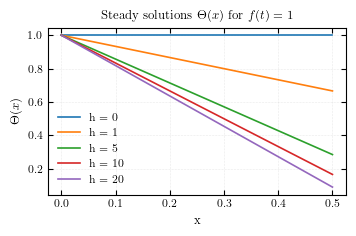

In [ ]:

for h in [0,1,5,10,20]:
    
    solver.h = h
    solver._build_matrices() # Matrix B depend on h and has to be rebuild
    
    f = np.ones(nt)
    
    g = solver.solve(f)[:,-1]

    # Fit lineare
    m, b_fit = np.polyfit(solver.x_array, g, 1)

    print("Slope (m):", m)
    print("Intercept (b):", b_fit)
    print(f"Expected Slope (m): {-h/(1+h*L)}")

    #plt.plot(solver.x_array, m*solver.x_array+b_fit, label=f"h = {h}")
    plt.plot(solver.x_array, g, label=f"h = {h}")

plt.legend()
plt.title(r"Steady solutions $\Theta(x)$ for $f(t) = 1$")
plt.xlabel("x")
plt.ylabel(r"$\Theta(x)$")
plt.grid()
plt.savefig("../assets/stationary_solution.pdf")
plt.show()